# 2026 OIBC 태양광 집합자원 — EDA v2

**과제**: 253개 발전소를 G1/G2로 나누고(구성), 집합별 시간 발전량을 하루 전(전일 17시)에 예측한다.
**v2에서 바뀐 점**: v1(`archive/eda_phase1_v1.ipynb`)의 계산 오류를 고치고, 점수식 관점의 분석(검증 하네스, 구성 headroom)을 추가했다. 계획서는 `docs/eda_preprocessing_plan.md`.
공통 정의(점수식, 로더, 태양 기하, 고장일 탐지, 구성 탐색)는 `src_tools/oibc_common.py`에 있어 이후 모델링에서도 그대로 쓴다.

| # | 분석 | 이 절이 정하는 것 |
|---|---|---|
| 1 | 로드·무결성 | 키 중복, 기간, k 정의 |
| 2 | 점수식 해부 | 무엇이 점수를 움직이는가 |
| 3 | 발전소 메타·편입 시점 | 검증 설계의 제약 |
| 4 | 발전량 품질 | 학습에서 뺄 행 |
| 5 | 예보 품질 | 결측 대체 규칙, 연도별 드리프트 |
| 6 | 맑은날 지수·시간 정렬 | 타깃 정규화, 병합 키 |
| 7 | 기상–발전 관계 | 핵심 변수, 라운드 |
| 8 | 예보 vs 실측 | 라운드별 예보 품질 (진단) |
| 9 | 검증 하네스 | 가상 평가연도 점수 |
| 10 | 구성 headroom | 구성에 쏟을 노력의 크기 |
| 11 | 페널티가 쌓이는 곳 | 시간대·월 집중도 |
| 12 | 요약 | 결정 사항 |

## 0. 환경

In [1]:
import sys, gc, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from cycler import cycler

# src_tools/ 를 import 경로에 추가 (노트북은 analysis_lab/ 에서 실행)
SRC = next(p / 'src_tools' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src_tools' / 'oibc_common.py').exists())
sys.path.insert(0, str(SRC))
from oibc_common import (DATA, ROOT, TZ, VALID_FROM, CAP_MIN_FRAC, PENALTY_RATE,
                         load_sites, load_generation, load_smp, load_forecast, fill_round_gaps,
                         dead_days, drop_dead, k_weight, day_of, score, group_penalty, local_search)
warnings.filterwarnings('ignore')
OUT = ROOT / 'outputs' / 'eda'; OUT.mkdir(parents=True, exist_ok=True)

# 차트 공통: 고정 순서 팔레트, 옅은 격자, 얇은 마크
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
BLUE, ORANGE, AQUA = PAL[:3]
MUTED = '#898781'
plt.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 100, 'font.size': 10,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.prop_cycle': cycler(color=PAL),
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'lines.linewidth': 2, 'legend.frameon': False,
})
pd.set_option('display.width', 160)
print(sys.executable)
print(f'pandas {pd.__version__} | numpy {np.__version__} | data: {DATA}')

C:\Users\109so\miniconda3\envs\bio_proj\python.exe
pandas 2.3.3 | numpy 2.2.6 | data: C:\Users\109so\OneDrive\Desktop\학교\compete\oibc\01_participant_dataset


## 1. 데이터 로드와 무결성

In [2]:
sites = load_sites()
gen = load_generation(sites)            # cf, 태양고도(elev), 날짜(date, 우측닫힘 기준) 포함
smp_tr, smp_te = load_smp('train'), load_smp('test')

print(f'sites {len(sites)}개, 총용량 {sites.capacity_kw.sum():,.1f} kW')
print(f'generation {len(gen):,}행  {gen.ts.min()} ~ {gen.ts.max()}')
print(f'  (site_id, ts) 중복: {gen.duplicated(["site_id", "ts"]).sum()}')
print(f'smp train {len(smp_tr):,}행  {smp_tr.ts.min()} ~ {smp_tr.ts.max()}')
print(f'smp test  {len(smp_te):,}행  {smp_te.ts.min()} ~ {smp_te.ts.max()}  ← 채점 시각·SMP·k 가 모두 주어짐')
assert (smp_te.k.to_numpy() == k_weight(smp_te.ts)).all()
print('  smp.csv 의 k 와 "시가 11~15 → 3" 규칙: 일치')

sites 253개, 총용량 42,655.4 kW
generation 4,392,566행  2021-01-19 13:00:00+09:00 ~ 2025-06-01 00:00:00+09:00


  (site_id, ts) 중복: 0
smp train 38,688행  2021-01-01 01:00:00+09:00 ~ 2025-06-01 00:00:00+09:00
smp test  8,760행  2025-06-01 01:00:00+09:00 ~ 2026-06-01 00:00:00+09:00  ← 채점 시각·SMP·k 가 모두 주어짐
  smp.csv 의 k 와 "시가 11~15 → 3" 규칙: 일치


## 2. 점수식 해부 — 무엇이 점수를 움직이는가

$$S=\sum_{g}\sum_t \mathrm{SMP}_t A_{g,t} \;-\; 0.10\sum_{g}\sum_t \mathrm{SMP}_t\, k_t\,|F_{g,t}-A_{g,t}|,\qquad g\in\{G1,G2\}$$

**(1) 수익항은 상수다.** 253개소가 모두 G1 아니면 G2 에 들어가므로 $A_{G1,t}+A_{G2,t}$ 는 전체 실적이다. 수익항은 구성에도 예측에도 영향을 받지 않는다. 대회 목표의 "총량 고정"이 이 뜻이고, **팀 간 점수 차이는 전부 페널티 항에서 난다.** (v1 계획서의 "좋은 발전소를 많이 넣을수록 수익↑"은 틀렸다.)

**(2) 구성의 효과는 두 집합 오차의 부호에서 나온다.** 집합 오차 $e_g=F_g-A_g$ 에 대해
$$|e_1|+|e_2| = |e_1+e_2| + 2\min(|e_1|,|e_2|)\cdot\mathbb{1}[e_1e_2<0]$$
두 집합이 **같은 방향으로** 틀리면 추가 손실이 없고, 반대 방향이면 작은 쪽 오차의 2배를 더 낸다. 따라서 하한은 "전체를 한 포트폴리오로 예측했을 때의 페널티"이고, 각 집합을 **전체의 축소 복제본**(지역·관측지점·규모가 고르게 섞인 집합)으로 만들수록 하한에 가까워진다. 지역별로 나누는 구성이 최악이다. → §10 에서 수치로 확인.

**(3) 시각별 최적 예측값은 가중치와 무관하다.** 한 시각의 손실이 $w_t|F-A|$ 이므로 $w_t>0$ 이면 최적점은 $A$ 의 **조건부 중앙값**이다. SMP·k 는 (a) 모델이 어느 시각을 더 잘 맞추도록 용량을 쓸지, (b) 검증 지표, (c) 구성 목적함수에서만 작동한다. SMP=0 인 시각은 오차가 공짜다.

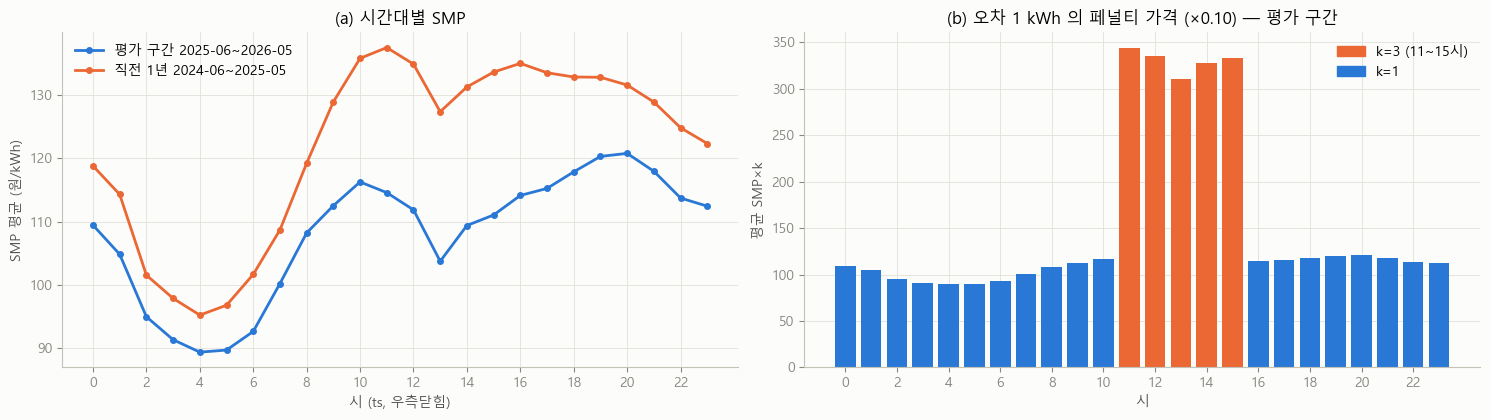

평가 구간 SMP 평균 108.0원 | 0원 시각 18개 | k=3 시각 1,825개
SMP 최저 4시 89.4원 / 최고 20시 120.8원
11~15시 평균 페널티 가격 ÷ 나머지 주간(7~10, 16~19시): 2.92배


In [3]:
te = smp_te.assign(hour=smp_te.ts.dt.hour)
by_h = te.groupby('hour').agg(smp=('smp', 'mean'), w=('w', 'mean'))
prev = smp_tr[smp_tr.ts >= VALID_FROM]
prev_h = prev.groupby(prev.ts.dt.hour).smp.mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
ax = axes[0]
ax.plot(by_h.index, by_h.smp, marker='o', ms=4, label='평가 구간 2025-06~2026-05')
ax.plot(prev_h.index, prev_h.values, marker='o', ms=4, label='직전 1년 2024-06~2025-05')
ax.set(xlabel='시 (ts, 우측닫힘)', ylabel='SMP 평균 (원/kWh)', title='(a) 시간대별 SMP', xticks=range(0, 24, 2))
ax.legend()
ax = axes[1]
ax.bar(by_h.index, by_h.w, color=np.where(by_h.index.isin(range(11, 16)), ORANGE, BLUE), width=0.8)
ax.set(xlabel='시', ylabel='평균 SMP×k', title='(b) 오차 1 kWh 의 페널티 가격 (×0.10) — 평가 구간', xticks=range(0, 24, 2))
ax.legend(handles=[Patch(color=ORANGE, label='k=3 (11~15시)'), Patch(color=BLUE, label='k=1')])
plt.tight_layout(); plt.show()

day_h = [7, 8, 9, 10, 16, 17, 18, 19]
print(f'평가 구간 SMP 평균 {te.smp.mean():.1f}원 | 0원 시각 {int((te.smp == 0).sum())}개 | k=3 시각 {int((te.k == 3).sum()):,}개')
print(f'SMP 최저 {by_h.smp.idxmin()}시 {by_h.smp.min():.1f}원 / 최고 {by_h.smp.idxmax()}시 {by_h.smp.max():.1f}원')
print(f'11~15시 평균 페널티 가격 ÷ 나머지 주간(7~10, 16~19시): {by_h.w[11:16].mean() / by_h.w[day_h].mean():.2f}배')

## 3. 발전소 메타와 편입 시점 — 검증 설계의 제약

**왜?** 학습 이력이 짧은 발전소가 많으면 발전소별 개별 모델은 성립하지 않고(→ 발전소를 섞어 학습하는 pooled 모델), 가상 평가연도의 경계도 이에 맞춰야 한다.

count     253.0
mean      168.6
std       223.5
min        14.4
25%        85.2
50%        99.4
75%       100.0
max      1387.5



100 kW 이하 203개 | 용량 상위 10개가 총용량의 24.7%
편입 연도별 발전소 수: {2021: 31, 2022: 49, 2023: 68, 2024: 105}
가상 평가연도 시작(2024-06-01) 이후 편입: 48개 ← 그 해에 학습 이력 없음
실제 평가 시작 시점 이력 1년 미만: 48개 (최단 158일)
WA 지점 61개, 지점당 발전소 중앙값 2개, 최대 20개
WB 지점 73개, 지점당 발전소 중앙값 2개, 최대 18개


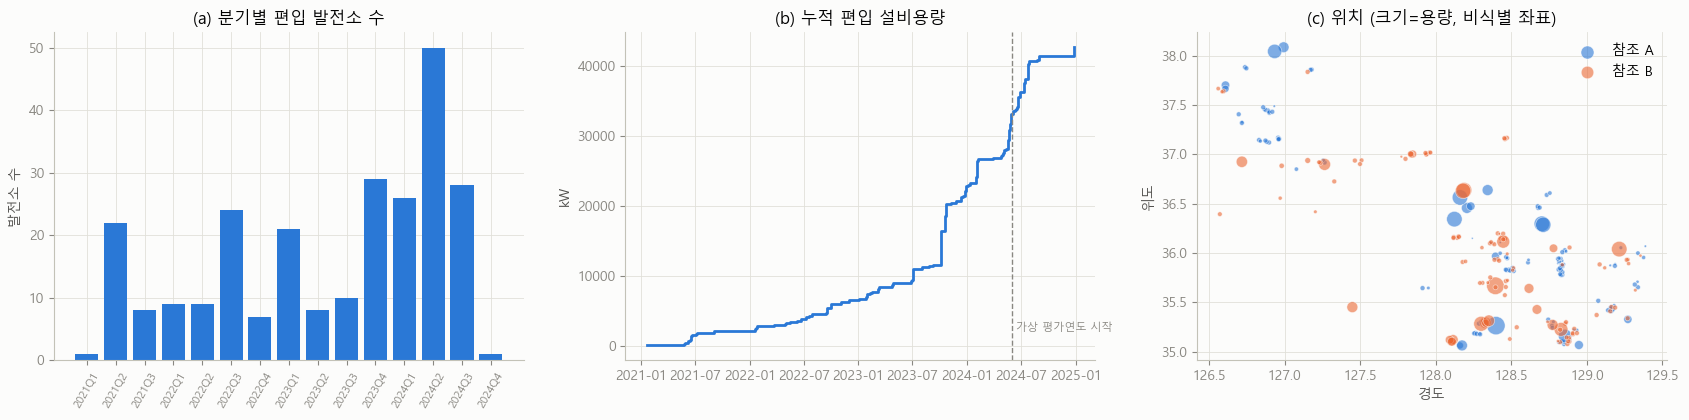

In [4]:
meta = sites.set_index('site_id').join(gen.groupby('site_id').ts.min().rename('start'))
meta['hist_days_at_test'] = (pd.Timestamp('2025-06-01 01:00', tz=TZ) - meta.start).dt.days

print(meta.capacity_kw.describe().round(1).to_string())
print(f'\n100 kW 이하 {(meta.capacity_kw <= 100).sum()}개 | 용량 상위 10개가 총용량의 {meta.capacity_kw.nlargest(10).sum() / meta.capacity_kw.sum() * 100:.1f}%')
print('편입 연도별 발전소 수:', meta.start.dt.year.value_counts().sort_index().to_dict())
print(f'가상 평가연도 시작({VALID_FROM:%Y-%m-%d}) 이후 편입: {(meta.start >= VALID_FROM).sum()}개 ← 그 해에 학습 이력 없음')
print(f'실제 평가 시작 시점 이력 1년 미만: {(meta.hist_days_at_test < 365).sum()}개 (최단 {meta.hist_days_at_test.min()}일)')
for p in ['wa', 'wb']:
    n = meta.groupby(f'{p}_station').size()
    print(f'{p.upper()} 지점 {len(n)}개, 지점당 발전소 중앙값 {n.median():.0f}개, 최대 {n.max()}개')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
q = meta.start.dt.to_period('Q').astype(str).value_counts().sort_index()
axes[0].bar(q.index, q.values, color=BLUE)
axes[0].tick_params(axis='x', rotation=60, labelsize=8)
axes[0].set(title='(a) 분기별 편입 발전소 수', ylabel='발전소 수')
cum = meta.sort_values('start').capacity_kw.cumsum()
axes[1].step(meta.sort_values('start').start, cum, where='post', color=BLUE)
axes[1].axvline(VALID_FROM, color=MUTED, ls='--', lw=1)
axes[1].text(VALID_FROM, cum.max() * 0.05, ' 가상 평가연도 시작', color=MUTED, fontsize=8)
axes[1].set(title='(b) 누적 편입 설비용량', ylabel='kW')
for g_, c in [('A', BLUE), ('B', ORANGE)]:
    m_ = meta[meta.current_group == g_]
    axes[2].scatter(m_.lon, m_.lat, s=m_.capacity_kw / 8, color=c, alpha=0.6, edgecolors='white', linewidths=0.5, label=f'참조 {g_}')
axes[2].set(title='(c) 위치 (크기=용량, 비식별 좌표)', xlabel='경도', ylabel='위도')
axes[2].legend()
plt.tight_layout(); plt.show()

## 4. 발전량 품질 — 학습에서 뺄 것

v1 의 "전 기간 존재율 ≥95% 발전소 0/253" 은 **편입 이전 기간을 결측으로 센 착시**였다. 편입 이후만 보면 빈 시각은 거의 없다. 진짜 문제는 행은 있는데 0 이 찍힌 **정지·고장 일**이다.

In [5]:
span = gen.groupby('site_id').ts.agg(['min', 'max', 'size'])
span['cov'] = span['size'] / ((span['max'] - span['min']) / pd.Timedelta(hours=1) + 1)
print(f'편입 이후 커버리지: 최소 {span["cov"].min() * 100:.3f}%, 평균 {span["cov"].mean() * 100:.4f}%')
print(f'마지막 시각이 학습 구간 끝이 아닌 발전소: {(span["max"] != span["max"].max()).sum()}개')
print(f'음수 energy {(gen.energy < 0).sum()}건 (최소 {gen.energy.min()}) → 0 으로 클리핑')
print(f'CF > 1.0 {(gen.cf > 1).sum()}건 (최대 {gen.cf.max():.3f}) → baseline 의 1.2 클리핑은 실효 없음')
print(f'태양고도 ≤ 0 시각의 발전량 비중 {gen.energy[gen.elev <= 0].sum() / gen.energy.sum() * 100:.2f}% → 야간 0 고정 안전')
p99 = gen[gen.elev > 20].groupby('site_id').cf.quantile(0.99)
print(f'발전소별 p99 CF(고도>20°) {p99.min():.3f} ~ {p99.max():.3f} → 설비용량 값 신뢰 가능')

편입 이후 커버리지: 최소 99.980%, 평균 99.9999%
마지막 시각이 학습 구간 끝이 아닌 발전소: 0개
음수 energy 40건 (최소 -1.0) → 0 으로 클리핑
CF > 1.0 9건 (최대 1.034) → baseline 의 1.2 클리핑은 실효 없음
태양고도 ≤ 0 시각의 발전량 비중 0.10% → 야간 0 고정 안전


발전소별 p99 CF(고도>20°) 0.743 ~ 0.911 → 설비용량 값 신뢰 가능


정지·고장 추정 site-day 729개 = 전체의 0.40%, 발전소 49개
정지일 상위 발전소: {'PV059': 142, 'PV246': 142, 'PV073': 127, 'PV011': 40, 'PV211': 38, 'PV208': 25, 'PV117': 16, 'PV104': 14}
같은 날 5개소 이상 동시 정지: 2일 (계통·출력제어성 이벤트 후보)
정지일 밖에서 혼자 0 인 시각 1,531개, 발전소 152개 → 학습 제외 후보(시각 단위)


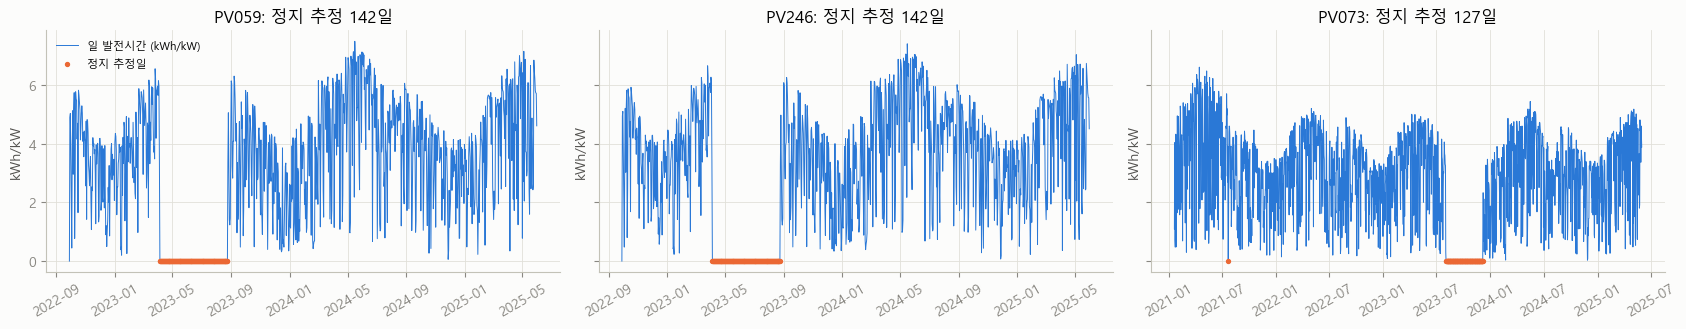

In [6]:
dd = dead_days(gen)                       # 해 뜬 시간(고도>5°) 일 발전량 ≤ 용량×1%
n_site_days = gen[gen.elev > 5].groupby(['site_id', 'date']).ngroups
top = dd.groupby('site_id').size().sort_values(ascending=False)
print(f'정지·고장 추정 site-day {len(dd):,}개 = 전체의 {len(dd) / n_site_days * 100:.2f}%, 발전소 {dd.site_id.nunique()}개')
print('정지일 상위 발전소:', top.head(8).to_dict())
many = dd.groupby('date').size()
print(f'같은 날 5개소 이상 동시 정지: {(many >= 5).sum()}일 (계통·출력제어성 이벤트 후보)')
dd.to_parquet(OUT / 'dead_days.parquet', index=False)

# 부분 정지: 다른 발전소는 잘 도는데(동시각 중앙 CF≥0.3) 혼자 0 인 시각
day = gen[gen.elev > 20]
iso = day[(day.cf <= 0.02) & (day.groupby('ts').cf.transform('median') >= 0.3)]
iso = drop_dead(iso, dd)
print(f'정지일 밖에서 혼자 0 인 시각 {len(iso):,}개, 발전소 {iso.site_id.nunique()}개 → 학습 제외 후보(시각 단위)')

daily = gen.groupby(['site_id', 'date']).agg(e=('energy', 'sum'), cap=('capacity_kw', 'first'))
fig, axes = plt.subplots(1, 3, figsize=(17, 3.4), sharey=True)
for ax, s in zip(axes, top.index[:3]):
    d_ = daily.loc[s]
    ax.plot(d_.index, d_.e / d_.cap, lw=0.7, color=BLUE, label='일 발전시간 (kWh/kW)')
    bad = dd[dd.site_id == s]
    ax.scatter(bad.date, np.zeros(len(bad)), s=8, color=ORANGE, label='정지 추정일', zorder=3)
    ax.set(title=f'{s}: 정지 추정 {len(bad)}일', ylabel='kWh/kW')
    ax.tick_params(axis='x', rotation=30)
axes[0].legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()
del day, iso; _ = gc.collect()

## 5. 예보 품질 — 결측 대체 규칙과 드리프트

v1 은 `isnull()` 로 평가 구간 결측을 찾고 "결측 없음"이라고 했지만, README 의 264개는 **행 자체가 없는** 결측이다. (지점×라운드×시각) 격자로 다시 세야 보인다.

In [7]:
KEY_A = ['wa_cloud', 'wa_humidity', 'wa_temp']
KEY_B = ['wb_cloud', 'wb_rel_hum', 'wb_uv_idx', 'wb_ceiling', 'wb_vis', 'wb_precip_prob', 'wb_temp']
fa_tr, fa_te = load_forecast('wa', 'train', KEY_A), load_forecast('wa', 'test', KEY_A)
fb_tr, fb_te = load_forecast('wb', 'train', KEY_B), load_forecast('wb', 'test', KEY_B)
test_idx = pd.DatetimeIndex(smp_te.ts)

def grid_missing(f, p, index):
    st = f'{p}_station'
    full = pd.MultiIndex.from_product([f[st].unique(), [10, 17], index], names=[st, 'round', 'ts'])
    return full.difference(pd.MultiIndex.from_frame(f[[st, 'round', 'ts']])).to_frame(index=False)

for name, f, p in [('WA test', fa_te, 'wa'), ('WB test', fb_te, 'wb')]:
    m_ = grid_missing(f, p, test_idx)
    print(f'{name}: {len(f):,}행, 격자 대비 빠진 행 {len(m_)}')
    if len(m_):
        both = m_.groupby([f'{p}_station', 'ts']).size().eq(2).sum()
        m_['date'] = day_of(m_.ts).dt.strftime('%Y-%m-%d').to_numpy()
        print(f'  지점-라운드 {m_.groupby([f"{p}_station", "round"]).ngroups}개, {m_.date.nunique()}일, 두 라운드가 모두 빠진 (지점,시각) {both}개')
        print('  날짜·라운드별:', m_.groupby(['date', 'round']).size().to_dict())
fa_te_f = fill_round_gaps(fa_te, 'wa', test_idx)
print(f'→ 같은 지점·시각의 다른 라운드로 대체 후 남은 결측 행: {fa_te_f[KEY_A].isna().any(axis=1).sum()}')

for name, f, p in [('WA train', fa_tr, 'wa'), ('WB train', fb_tr, 'wb')]:
    idx = pd.date_range(f.ts.min(), f.ts.max(), freq='h')
    m_ = grid_missing(f, p, idx)
    print(f'{name}: {f.ts.min():%Y-%m-%d} ~ {f.ts.max():%Y-%m-%d}, 격자 대비 빠진 행 {len(m_):,} ({len(m_) / (len(f) + len(m_)) * 100:.2f}%)')
print(f'WB train 강수 계열 NaN: {fb_tr.wb_precip_prob.isna().sum():,}행 (LightGBM 은 NaN 을 그대로 처리)')

WA test: 1,068,456행, 격자 대비 빠진 행 264
  지점-라운드 14개, 12일, 두 라운드가 모두 빠진 (지점,시각) 0개
  날짜·라운드별: {('2026-01-24', 10): 42, ('2026-02-07', 17): 23, ('2026-02-13', 10): 23, ('2026-03-11', 10): 23, ('2026-03-27', 17): 18, ('2026-03-28', 17): 12, ('2026-04-01', 10): 23, ('2026-04-03', 17): 23, ('2026-04-19', 10): 11, ('2026-04-22', 17): 6, ('2026-05-22', 10): 37, ('2026-05-25', 10): 23}


WB test: 1,278,960행, 격자 대비 빠진 행 0


→ 같은 지점·시각의 다른 라운드로 대체 후 남은 결측 행: 0


WA train: 2021-01-01 ~ 2025-06-01, 격자 대비 빠진 행 9,580 (0.20%)


WB train: 2021-01-01 ~ 2025-06-01, 격자 대비 빠진 행 26,544 (0.47%)
WB train 강수 계열 NaN: 1,298행 (LightGBM 은 NaN 을 그대로 처리)


In [8]:
def fy(ts):  # 6월 시작 연도 (평가 구간과 같은 경계)
    return np.where(ts.dt.month >= 6, ts.dt.year, ts.dt.year - 1)

rows = []
for fa_, fb_ in [(fa_tr, fb_tr), (fa_te, fb_te)]:
    a = fa_[fa_.ts.dt.hour.between(11, 15)]
    b = fb_[fb_.ts.dt.hour.between(11, 15)]
    rows.append(a.groupby([fy(a.ts), 'round'])[['wa_cloud', 'wa_humidity']].mean()
                 .join(b.groupby([fy(b.ts), 'round'])[['wb_cloud', 'wb_rel_hum', 'wb_uv_idx']].mean()))
drift = pd.concat(rows)
drift.index.names = ['연도(6월~)', 'round']
print('11~15시 예보 평균 — 연도별 (2020 은 2021-01~05 만, 2025 가 평가 구간)')
print(drift.round(1).to_string())

11~15시 예보 평균 — 연도별 (2020 은 2021-01~05 만, 2025 가 평가 구간)
               wa_cloud  wa_humidity  wb_cloud  wb_rel_hum  wb_uv_idx
연도(6월~) round                                                        
2020    10         51.3         54.6      49.7        42.2        3.7
        17         53.1         54.6      50.0        42.7        3.7
2021    10         54.2         51.6      51.3        46.8        3.8
        17         54.2         51.7      51.6        46.7        3.8
2022    10         57.5         52.4      58.7        48.8        3.4
        17         57.6         52.7      58.6        48.9        3.4
2023    10         57.8         56.6      57.0        55.8        3.6
        17         58.3         56.7      56.5        55.8        3.6
2024    10         54.9         54.9      54.4        54.4        3.6
        17         55.2         55.0      54.3        54.4        3.5
2025    10         55.5         52.6      51.7        52.7        3.6
        17         55.7         52.

## 6. 맑은날 지수(CSI)와 시간 정렬

원 CF 는 해의 높이(일주기·계절)에 지배된다. 그래서 v1 의 상관 분석은 해가 높을 때 함께 커지는 변수(UV 지수, 기온)를 과대평가하고 운량을 과소평가했다.
여기서는 발전소별 **맑은날 기준 곡선** $\mathrm{CF}_{p95}$ = (발전소, 월, 시)별 CF 의 95% 분위수를 만들고 $\mathrm{CSI}=\mathrm{CF}/\mathrm{CF}_{p95}$ 로 정규화한다. 이 기준 곡선은 방위·음영·DC/AC 비처럼 발전소마다 다른 특성을 흡수하므로 모델 피처(또는 타깃 정규화)로도 쓸 수 있다. 단, 모델에 쓸 때는 **학습 기간 데이터로만** 계산해야 한다.

In [9]:
CSI_FROM = pd.Timestamp('2023-06-01 01:00', tz=TZ)
g = drop_dead(gen[(gen.ts >= CSI_FROM) & (gen.elev > 5)], dd)
g['month'], g['hour'] = g.ts.dt.month, g.ts.dt.hour
ref95 = g.groupby(['site_id', 'month', 'hour']).cf.quantile(0.95).rename('cf_ref')
g = g.join(ref95, on=['site_id', 'month', 'hour'])
g['csi'] = (g.cf / g.cf_ref.clip(lower=0.02)).clip(0, 1.5)
print(f'CSI 계산 행 {len(g):,} (2023-06 이후, 고도>5°, 정지일 제외)')

fa17 = fa_tr[fa_tr['round'] == 17].drop(columns='round')
fb17 = fb_tr[fb_tr['round'] == 17].drop(columns='round')
res = []
for sh in [-2, -1, 0, 1, 2]:
    f_ = fa17[['wa_station', 'ts', 'wa_cloud']].assign(ts=fa17.ts + pd.Timedelta(hours=sh))
    m_ = g[['wa_station', 'ts', 'csi', 'cf']].merge(f_, on=['wa_station', 'ts'])
    res.append((sh, m_.csi.corr(m_.wa_cloud), m_.cf.corr(m_.wa_cloud)))
al = pd.DataFrame(res, columns=['예보 이동(h)', 'corr(CSI, 운량)', 'corr(CF, 운량)']).set_index('예보 이동(h)')
print(al.round(4).to_string())
print(f'→ CSI 기준 |상관| 최대 이동: {al.iloc[:, 0].abs().idxmax():+d}h. 0h 와 차이가 미미하면 ts 그대로 병합한다.')

CSI 계산 행 1,579,454 (2023-06 이후, 고도>5°, 정지일 제외)


          corr(CSI, 운량)  corr(CF, 운량)
예보 이동(h)                             
-2              -0.5150       -0.3214
-1              -0.5271       -0.3361
 0              -0.5344       -0.3492
 1              -0.5339       -0.3555
 2              -0.5275       -0.3528
→ CSI 기준 |상관| 최대 이동: +0h. 0h 와 차이가 미미하면 ts 그대로 병합한다.


## 7. 기상–발전 관계 (CSI 기준)

**왜?** 해의 높이로 설명되지 않는 변동(구름·비)을 어떤 예보 변수가 설명하는지가 피처 우선순위를 정한다.

round 17, 2023-06 이후 주간 1,579,412행
                CF 상관 (v1 방식)  CSI 상관  CSI 순위상관
wa_humidity            -0.600  -0.567    -0.546
wa_cloud               -0.349  -0.534    -0.559
wb_rel_hum             -0.567  -0.518    -0.509
wb_ceiling              0.324   0.495     0.464
wb_cloud               -0.286  -0.470    -0.481
wb_precip_prob         -0.277  -0.446    -0.455
wb_uv_idx               0.640   0.341     0.389
wb_vis                  0.184   0.258     0.274
wa_temp                 0.161   0.062     0.060
wb_temp                 0.152   0.041     0.043


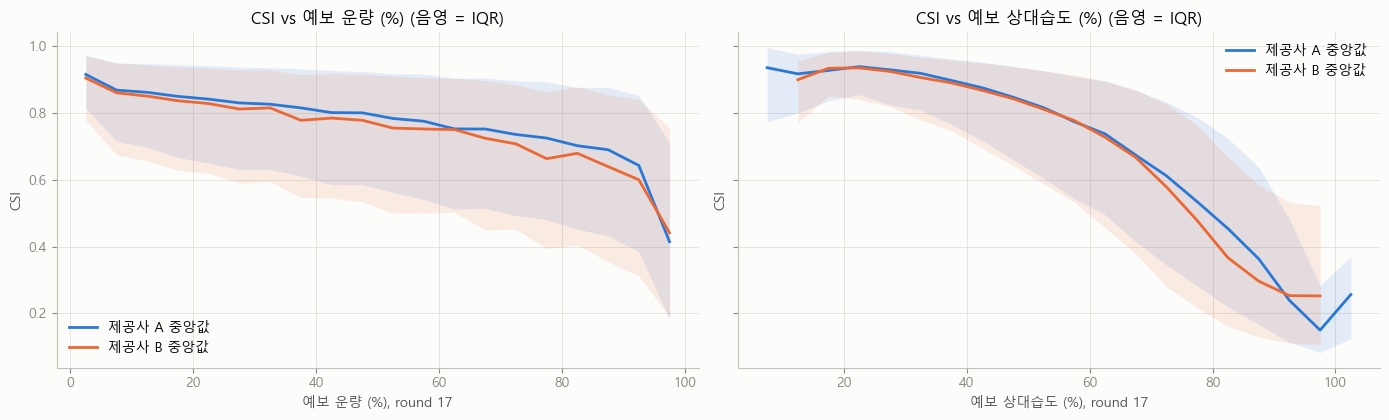

In [10]:
m = g.merge(fa17, on=['wa_station', 'ts']).merge(fb17, on=['wb_station', 'ts'])
VARS = KEY_A + KEY_B
tab = pd.DataFrame({
    'CF 상관 (v1 방식)': [m.cf.corr(m[v]) for v in VARS],
    'CSI 상관': [m.csi.corr(m[v]) for v in VARS],
    'CSI 순위상관': [m.csi.corr(m[v], method='spearman') for v in VARS],
}, index=VARS)
tab = tab.reindex(tab['CSI 상관'].abs().sort_values(ascending=False).index)
print(f'round 17, 2023-06 이후 주간 {len(m):,}행')
print(tab.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for ax, (va_, vb_, lab) in zip(axes, [('wa_cloud', 'wb_cloud', '운량 (%)'), ('wa_humidity', 'wb_rel_hum', '상대습도 (%)')]):
    for v, c, name in [(va_, BLUE, '제공사 A'), (vb_, ORANGE, '제공사 B')]:
        b = pd.cut(m[v], np.arange(0, 110, 5), include_lowest=True)
        q = m.groupby(b, observed=True).csi.quantile([0.25, 0.5, 0.75]).unstack()
        x = [i.mid for i in q.index]
        ax.plot(x, q[0.5], color=c, label=f'{name} 중앙값')
        ax.fill_between(x, q[0.25], q[0.75], color=c, alpha=0.12, lw=0)
    ax.set(xlabel=f'예보 {lab}, round 17', ylabel='CSI', title=f'CSI vs 예보 {lab} (음영 = IQR)')
    ax.legend()
plt.tight_layout(); plt.show()

In [11]:
# 라운드 10 vs 17 vs 평균 — 운량 예보가 CSI 를 얼마나 설명하나
for p, f in [('wa', fa_tr), ('wb', fb_tr)]:
    st, v = f'{p}_station', f'{p}_cloud'
    r = f.pivot_table(index=[st, 'ts'], columns='round', values=v).dropna()
    r.columns = ['r10', 'r17']
    r['avg'] = r.mean(axis=1)
    j = g[[st, 'ts', 'csi']].join(r, on=[st, 'ts'], how='inner')
    cs = {c: j.csi.corr(j[c]) for c in ['r10', 'r17', 'avg']}
    gap = (j.r17 - j.r10).abs()
    print(f'{p.upper()} 운량: corr(CSI) r10 {cs["r10"]:+.4f} | r17 {cs["r17"]:+.4f} | 평균 {cs["avg"]:+.4f}'
          f'  || 라운드 간 |차| 평균 {gap.mean():.1f}%p, 30%p 이상 {(gap >= 30).mean() * 100:.1f}%')

WA 운량: corr(CSI) r10 -0.5314 | r17 -0.5344 | 평균 -0.5473  || 라운드 간 |차| 평균 9.7%p, 30%p 이상 10.8%


WB 운량: corr(CSI) r10 -0.4620 | r17 -0.4694 | 평균 -0.4741  || 라운드 간 |차| 평균 4.9%p, 30%p 이상 6.1%


## 8. 예보 vs 실측 (진단용)

실측 기상은 평가 구간에 없으므로 모델 입력이 될 수 없다. 여기서는 라운드별 예보 품질을 비교하는 진단에만 쓴다. README 의 이상값은 NaN 으로 바꾼 뒤 계산한다(v1 은 9999 를 그대로 둬서 풍속 RMSE 가 22.4 로 나왔다). 제공사마다 '실측 운량'의 정의가 다를 수 있으므로 제공사 간 비교보다 **같은 제공사의 라운드 간 비교**에 의미가 있다.

In [12]:
owa = pd.read_parquet(DATA / 'train' / 'observed_wa.parquet', columns=['wa_station', 'ts', 'wa_cloud', 'wa_humidity', 'wa_temp'])
owb = pd.read_parquet(DATA / 'train' / 'observed_wb.parquet', columns=['wb_station', 'ts', 'wb_cloud', 'wb_rel_hum', 'wb_temp'])
for o in (owa, owb):
    o['ts'] = pd.to_datetime(o.ts)
owb.loc[owb.wb_cloud > 100, 'wb_cloud'] = np.nan

rows = []
for p, f, o, vars_ in [('A', fa_tr, owa, KEY_A), ('B', fb_tr, owb, ['wb_cloud', 'wb_rel_hum', 'wb_temp'])]:
    st = f'w{p.lower()}_station'
    for rnd in (10, 17):
        mm = f[(f['round'] == rnd) & f.ts.dt.hour.between(8, 17)].merge(o, on=[st, 'ts'], suffixes=('_f', '_o'))
        for v in vars_:
            e = (mm[v + '_f'] - mm[v + '_o']).dropna()
            rows.append({'제공사': p, '변수': v, 'round': rnd, 'bias': e.mean(), 'MAE': e.abs().mean()})
acc = pd.DataFrame(rows).pivot_table(index=['제공사', '변수'], columns='round', values=['bias', 'MAE'])
print('주간(8~17시) 예보 오차, round 10 vs 17')
print(acc.round(2).to_string())
del owa, owb, fa_te_f; _ = gc.collect()

주간(8~17시) 예보 오차, round 10 vs 17
                   MAE         bias      
round               10     17    10    17
제공사 변수                                   
A   wa_cloud     17.15  15.52  3.96  4.16
    wa_humidity   6.08   5.55  0.18  0.31
    wa_temp       1.53   1.48 -0.02 -0.03
B   wb_cloud     25.01  24.27  7.37  7.26
    wb_rel_hum    9.16   9.09 -2.93 -2.90
    wb_temp       1.32   1.30  0.28  0.29


## 9. 검증 하네스 — 가상 평가연도 점수

실제 평가는 "2025-05-31 까지의 데이터로 학습 → 2025-06~2026-05 한 해를 한 번에 예측"이다. 같은 구조로 **학습 ≤ 2024-05-31, 검증 2024-06-01 01:00 ~ 2025-06-01 00:00** 을 잡고 대회 점수식(`oibc_common.score`)을 그대로 계산한다. 이후 모든 실험(피처, 라운드, 보정, 구성)은 이 점수로 판정한다.

- 빠른 기준 모델: baseline.py 의 피처·하이퍼파라미터를 그대로 쓰되 round 17 만, 학습 2022-06 ~ 2024-05, 정지일 제외.
- 비교 기준: 기후값(발전소×월×시 CF 중앙값) 예측.
- 가중치: 학습 구간 SMP × k.

In [13]:
import lightgbm as lgb
WA_COLS = ['wa_cloud', 'wa_temp', 'wa_humidity', 'wa_rain', 'wa_wind_speed', 'wa_ground_press']
WB_COLS = ['wb_cloud', 'wb_temp', 'wb_rel_hum', 'wb_uv_idx', 'wb_precip_prob', 'wb_total_liq', 'wb_vis', 'wb_wind_speed', 'wb_dew_point']
FEATS = WA_COLS + WB_COLS + ['elev', 'azim', 'cosz', 'doy_sin', 'doy_cos', 'hour', 'cap', 'lat', 'lon']
TRAIN_FROM = pd.Timestamp('2022-06-01 01:00', tz=TZ)
del fa_tr, fb_tr, fa_te, fb_te, fa17, fb17, m; gc.collect()

fa = load_forecast('wa', 'train', WA_COLS)
fb = load_forecast('wb', 'train', WB_COLS)
fa = fa[(fa['round'] == 17) & (fa.ts >= TRAIN_FROM)].drop(columns='round')
fb = fb[(fb['round'] == 17) & (fb.ts >= TRAIN_FROM)].drop(columns='round')
d = (gen[gen.ts >= TRAIN_FROM].merge(fa, on=['wa_station', 'ts'], how='left')
                              .merge(fb, on=['wb_station', 'ts'], how='left'))
doy = d.ts.dt.dayofyear
d['doy_sin'], d['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
d['hour'], d['cap'], d['month'] = d.ts.dt.hour, d.capacity_kw, d.ts.dt.month
tr = drop_dead(d[(d.ts < VALID_FROM) & (d.elev > 0)], dd)
va = d[d.ts >= VALID_FROM].copy()
del d, fa, fb; gc.collect()

model = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.06, num_leaves=127, min_child_samples=200,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=-1, random_state=0)
model.fit(tr[FEATS].astype('float32'), tr.cf.clip(0, 1.2))
day_mask = va.elev.to_numpy() > 0
va['pred'] = np.where(day_mask, np.clip(model.predict(va[FEATS].astype('float32')), 0, None), 0) * va.cap

c1 = tr.groupby(['site_id', 'month', 'hour']).cf.median().rename('c1')
c0 = tr.groupby(['month', 'hour']).cf.median().rename('c0')
va = va.join(c1, on=['site_id', 'month', 'hour']).join(c0, on=['month', 'hour'])
va['clim'] = np.where(day_mask, va.c1.fillna(va.c0), 0) * va.cap
print(f'학습 {len(tr):,}행 / 검증 {len(va):,}행')

grp = sites.set_index('site_id').current_group.map({'A': 'G1', 'B': 'G2'})
va['group'] = va.site_id.map(grp)
act = va.groupby(['group', 'ts'], as_index=False).energy.sum().rename(columns={'energy': 'kwh'})
scores = {}
for name, col in [('빠른 기준 모델', 'pred'), ('기후값', 'clim')]:
    fc = va.groupby(['group', 'ts'], as_index=False)[col].sum().rename(columns={col: 'kwh'})
    s = scores[name] = score(act, fc, smp_tr)
    print(f'[{name}] 참조 구성 · 검증연도 전체 발전소: 수익 {s["revenue"]:,.0f} | 페널티 {s["penalty"]:,.0f} ({s["penalty_pct"]:.2f}% of 수익)')
print(f'기준 모델의 페널티는 기후값의 {scores["빠른 기준 모델"]["penalty"] / scores["기후값"]["penalty"] * 100:.0f}%')

학습 956,643행 / 검증 2,170,645행


[빠른 기준 모델] 참조 구성 · 검증연도 전체 발전소: 수익 7,497,583,487 | 페널티 223,789,723 (2.98% of 수익)
[기후값] 참조 구성 · 검증연도 전체 발전소: 수익 7,497,583,487 | 페널티 516,312,377 (6.89% of 수익)
기준 모델의 페널티는 기후값의 43%


## 10. 구성 headroom — 구성에 얼마나 공을 들일 가치가 있나

§2 의 항등식에 따라, 같은 예측에서 **구성만 바꿨을 때** 페널티가 얼마나 변하는지 본다. 검증연도 전체 이력이 있는 발전소(편입 < 2024-06-01)만 쓴다.

- **하한**: 전체를 한 포트폴리오로 봤을 때 $\sum_t w_t|\sum_i e_{i,t}|$
- **참조 구성**, **무작위 구성 300개**(용량 하한 비율 46.9% 유지), **남/북 지리 분할**
- **최적화 구성**: 발전소 1개씩 옮기는 국소탐색(`local_search`). 같은 데이터로 최적화하고 평가하면 낙관적이므로 **홀수 달로 최적화 → 짝수 달로 평가**(반대 방향도)한 표본 외 수치를 본다.

발전소 205개 × 8,760시각, 실적 빈칸 0개(0 처리)


하한(한 포트폴리오) 페널티 = 178,703,230원  → 아래는 하한 대비 초과 %
최적화 구성 (표본 외 평균)          0.85
참조 구성 (current_group)     1.85
무작위 구성 300개 평균            1.60
무작위 구성 300개 최악            3.47
남/북 지리 분할                11.96
(참고) 발전소별 오차를 상쇄 없이 더한 값: 하한 대비 +74.7%

표본 외 검증:
         최적화 기간(표본 내)  평가 기간: 최적화 구성  평가 기간: 참조 구성
방향                                                
홀수달→짝수달          0.31           1.00          2.23
짝수달→홀수달          0.64           0.69          1.50


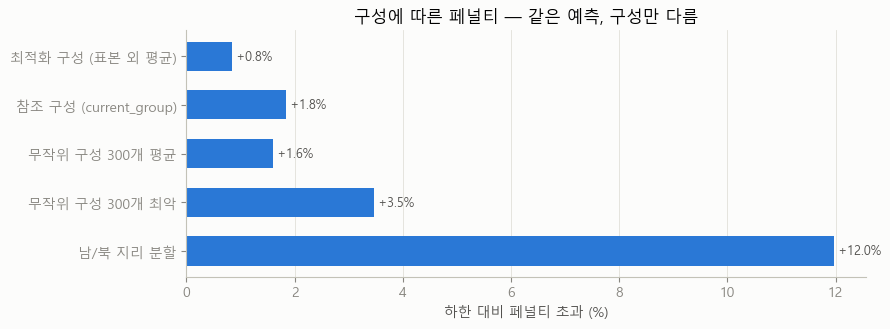

In [14]:
full_sites = sorted(meta.index[meta.start < VALID_FROM])
v = va[va.site_id.isin(full_sites)]
A = v.pivot(index='ts', columns='site_id', values='energy').reindex(columns=full_sites)
P = v.pivot(index='ts', columns='site_id', values='pred').reindex(columns=full_sites)
print(f'발전소 {len(full_sites)}개 × {len(A):,}시각, 실적 빈칸 {int(A.isna().sum().sum())}개(0 처리)')
P, A = P.where(A.notna(), 0), A.fillna(0)
R = (P - A).to_numpy()
w = smp_tr.set_index('ts').w.reindex(A.index).to_numpy()
cap = meta.capacity_kw.reindex(full_sites).to_numpy()
ref = (meta.current_group.reindex(full_sites) == 'A').to_numpy()
lat = meta.lat.reindex(full_sites).to_numpy()
month = A.index.month.to_numpy()
rng = np.random.default_rng(0)

def feasible(x):
    f = cap[x].sum() / cap.sum()
    return CAP_MIN_FRAC <= f <= 1 - CAP_MIN_FRAC

def rand_split():
    while True:
        x = rng.random(len(cap)) < 0.5
        if feasible(x):
            return x

lb = float(w @ np.abs(R.sum(1)))
over = lambda p, base=lb: (p / base - 1) * 100
rand = np.array([group_penalty(R, rand_split(), w) for _ in range(300)])
order = np.argsort(lat)
north = np.zeros(len(cap), bool)
north[order[np.cumsum(cap[order]) / cap.sum() > 0.5]] = True
site_sum = float(w @ np.abs(R).sum(1))

oos = []
for fit_m, eval_m, name in [(month % 2 == 1, month % 2 == 0, '홀수달→짝수달'), (month % 2 == 0, month % 2 == 1, '짝수달→홀수달')]:
    wf, we = w * fit_m, w * eval_m
    xs = [local_search(R, wf, x0, cap) for x0 in [ref] + [rand_split() for _ in range(4)]]
    x = min(xs, key=lambda x_: group_penalty(R, x_, wf))
    lbf, lbe = float(wf @ np.abs(R.sum(1))), float(we @ np.abs(R.sum(1)))
    oos.append({'방향': name, '최적화 기간(표본 내)': over(group_penalty(R, x, wf), lbf),
                '평가 기간: 최적화 구성': over(group_penalty(R, x, we), lbe), '평가 기간: 참조 구성': over(group_penalty(R, ref, we), lbe)})
oos = pd.DataFrame(oos).set_index('방향')

summary = pd.Series({
    '최적화 구성 (표본 외 평균)': oos['평가 기간: 최적화 구성'].mean(),
    '참조 구성 (current_group)': over(group_penalty(R, ref, w)),
    '무작위 구성 300개 평균': over(rand.mean()),
    '무작위 구성 300개 최악': over(rand.max()),
    '남/북 지리 분할': over(group_penalty(R, north, w)),
})
print(f'하한(한 포트폴리오) 페널티 = {PENALTY_RATE * lb:,.0f}원  → 아래는 하한 대비 초과 %')
print(summary.round(2).to_string())
print(f'(참고) 발전소별 오차를 상쇄 없이 더한 값: 하한 대비 +{over(site_sum):.1f}%')
print('\n표본 외 검증:'); print(oos.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(summary.index[::-1], summary.values[::-1], color=BLUE, height=0.6)
for y, val in enumerate(summary.values[::-1]):
    ax.text(val, y, f' +{val:.1f}%', va='center', fontsize=9, color='#52514e')
ax.set(xlabel='하한 대비 페널티 초과 (%)', title='구성에 따른 페널티 — 같은 예측, 구성만 다름')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

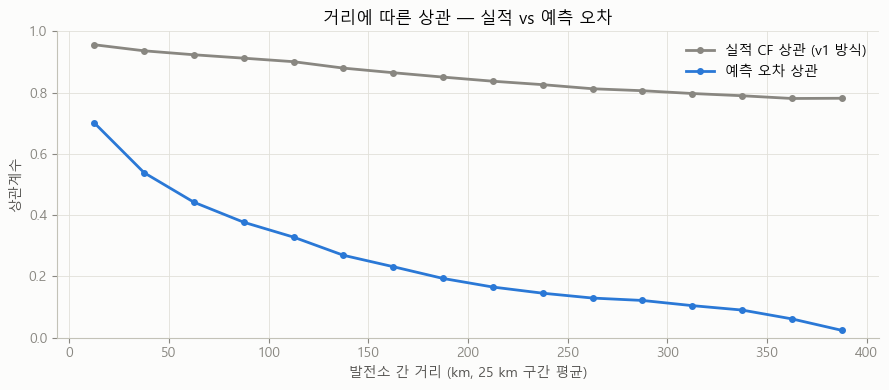

      실적 CF 상관 (v1 방식)  예측 오차 상관
mean             0.890     0.350
50%              0.906     0.350
min              0.702    -0.036


In [15]:
# 발전소 간 '실적 CF' 상관(v1 방식) vs '예측 오차' 상관 — 구성에 중요한 것은 뒤쪽
rows_day = A.sum(1).to_numpy() > 0
C_err = np.corrcoef((R[rows_day] / cap).T)
C_act = np.corrcoef((A.to_numpy()[rows_day] / cap).T)
la, lo = np.radians(lat), np.radians(meta.lon.reindex(full_sites).to_numpy())
dist = 2 * 6371 * np.arcsin(np.sqrt(np.sin((la[:, None] - la) / 2) ** 2 + np.cos(la[:, None]) * np.cos(la) * np.sin((lo[:, None] - lo) / 2) ** 2))
iu = np.triu_indices(len(cap), 1)
pairs = pd.DataFrame({'dist': dist[iu], '실적 CF 상관 (v1 방식)': C_act[iu], '예측 오차 상관': C_err[iu]})
pairs['bin'] = pd.cut(pairs.dist, np.arange(0, pairs.dist.max() + 25, 25))
curve = pairs.groupby('bin', observed=True)[['실적 CF 상관 (v1 방식)', '예측 오차 상관']].mean()

fig, ax = plt.subplots(figsize=(9, 4))
x = [b.mid for b in curve.index]
for col, c in zip(curve.columns, [MUTED, BLUE]):
    ax.plot(x, curve[col], marker='o', ms=4, color=c, label=col)
ax.set(xlabel='발전소 간 거리 (km, 25 km 구간 평균)', ylabel='상관계수', title='거리에 따른 상관 — 실적 vs 예측 오차', ylim=(0, 1))
ax.legend()
plt.tight_layout(); plt.show()
print(pairs[['실적 CF 상관 (v1 방식)', '예측 오차 상관']].describe().loc[['mean', '50%', 'min']].round(3).to_string())

## 11. 페널티가 쌓이는 곳 — 시간대·월

v1 은 SMP×k **가격**만으로 "11~15시가 주간 페널티의 61%"라고 했다. 실제 페널티는 가격 × 오차 크기이고, 오차도 한낮에 가장 크다. 검증연도의 실제 오차로 다시 계산한다(참조 구성).

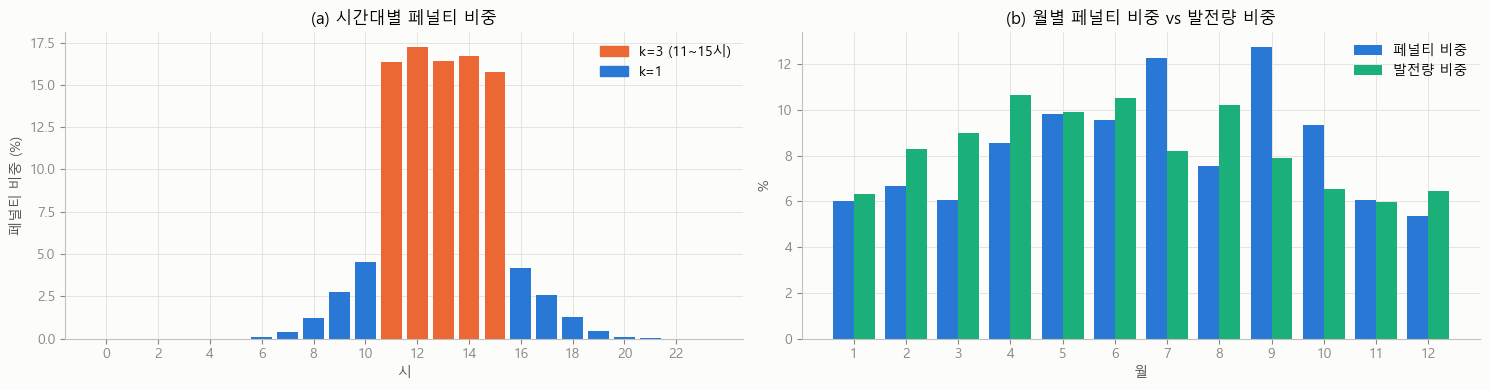

11~15시 페널티 비중: 82.5% (v1 의 가격 기준 추정 61%)
발전량 대비 페널티가 큰 달 (비중 비율): {9: 1.62, 7: 1.49, 10: 1.43, 11: 1.01}


In [16]:
pen_t = w * (np.abs(R[:, ref].sum(1)) + np.abs(R[:, ~ref].sum(1)))
hours = A.index.hour.to_numpy()
by_hour = pd.Series(pen_t).groupby(hours).sum() / pen_t.sum() * 100
by_month = pd.Series(pen_t).groupby(month).sum() / pen_t.sum() * 100
gen_month = pd.Series(A.sum(1).to_numpy()).groupby(month).sum()
gen_month = gen_month / gen_month.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(by_hour.index, by_hour.values, color=np.where(by_hour.index.isin(range(11, 16)), ORANGE, BLUE), width=0.8)
axes[0].set(xlabel='시', ylabel='페널티 비중 (%)', title='(a) 시간대별 페널티 비중', xticks=range(0, 24, 2))
axes[0].legend(handles=[Patch(color=ORANGE, label='k=3 (11~15시)'), Patch(color=BLUE, label='k=1')])
xm = np.arange(1, 13)
axes[1].bar(xm - 0.2, by_month.reindex(xm).values, width=0.4, color=BLUE, label='페널티 비중')
axes[1].bar(xm + 0.2, gen_month.reindex(xm).values, width=0.4, color=AQUA, label='발전량 비중')
axes[1].set(xlabel='월', ylabel='%', title='(b) 월별 페널티 비중 vs 발전량 비중', xticks=xm)
axes[1].legend()
plt.tight_layout(); plt.show()
print(f'11~15시 페널티 비중: {by_hour[11:16].sum():.1f}% (v1 의 가격 기준 추정 61%)')
ratio = (by_month / gen_month).sort_values(ascending=False)
print('발전량 대비 페널티가 큰 달 (비중 비율):', ratio.head(4).round(2).to_dict())

## 12. 요약

In [17]:
print('=' * 72)
print(f'점수   수익항은 구성·예측과 무관한 상수. 빠른 기준 모델의 페널티 ≈ 수익의 {scores["빠른 기준 모델"]["penalty_pct"]:.2f}%')
print(f'구성   하한 대비: 참조 +{summary.iloc[1]:.2f}%, 무작위 평균 +{summary.iloc[2]:.2f}%, 남/북 분할 +{summary.iloc[4]:.2f}%, 최적화(표본 외) +{summary.iloc[0]:.2f}%')
print(f'       → 구성으로 얻을 수 있는 몫은 페널티의 약 {summary.iloc[1] - summary.iloc[0]:.1f}%. 지역 분할만 피하면 된다.')
print(f'시간   11~15시가 페널티의 {by_hour[11:16].sum():.1f}%')
print(f'데이터 정지 추정 {len(dd):,} site-day / {dd.site_id.nunique()}개소, 편입 후 결측 거의 없음, 2024년 편입 {(meta.start.dt.year == 2024).sum()}개소')
print(f'예보   평가 WA 빠진 행은 다른 라운드로 전부 대체 가능, 시간 정렬 이동 없음(최적 {al.iloc[:, 0].abs().idxmax():+d}h)')
print('=' * 72)

점수   수익항은 구성·예측과 무관한 상수. 빠른 기준 모델의 페널티 ≈ 수익의 2.98%
구성   하한 대비: 참조 +1.85%, 무작위 평균 +1.60%, 남/북 분할 +11.96%, 최적화(표본 외) +0.85%
       → 구성으로 얻을 수 있는 몫은 페널티의 약 1.0%. 지역 분할만 피하면 된다.
시간   11~15시가 페널티의 82.5%
데이터 정지 추정 729 site-day / 49개소, 편입 후 결측 거의 없음, 2024년 편입 105개소
예보   평가 WA 빠진 행은 다른 라운드로 전부 대체 가능, 시간 정렬 이동 없음(최적 +0h)


**이 EDA 가 정한 것** (자세한 근거와 일정은 `docs/eda_preprocessing_plan.md`)

1. 승부처는 **예측 정확도, 특히 11~15시**다. 구성은 "지역별로 나누지 않기 + 마지막에 최종 모델 잔차로 국소탐색" 정도면 충분하다.
2. 학습에서 **정지·고장일을 제외**한다(`outputs/eda/dead_days.parquet`). 검증 실적에서는 빼지 않는다.
3. 평가 WA 빠진 행은 **같은 시각의 다른 라운드**로 채운다(`fill_round_gaps`).
4. 발전소별 개별 모델은 이력이 짧아 불가 → **pooled 모델 + 발전소 맑은날 기준 곡선 피처**.
5. 모든 실험은 §9 의 **가상 평가연도 점수**로 판정한다. 구성 최적화는 반드시 표본 외로 평가한다.